# Modeling: Multiple Logistic Regression

Research question: **Which factors are associated with the severity of road accidents with personal injury in Switzerland, in particular urban/rural and day/night?**

- **H1:** In rural areas the share of severe or fatal outcomes is higher than in urban areas.
- **H2:** At night the share of severe or fatal outcomes is higher than during the day.

**What this notebook does (in short):** The χ² tests in `02_eda.ipynb` compare groups *one factor at a time*. Here, a multiple logistic regression looks at urban/rural and day/night **at the same time** and holds accident type, road type and year constant. This shows whether the differences from the EDA remain once these other characteristics are taken into account. Afterwards the model is evaluated on unseen test data.

| Step | Content |
|---|---|
| 1 | Libraries and settings |
| 2 | Load the cleaned data and check it against the EDA |
| 3 | Model variables and decisions |
| 4 | Train/test split |
| 5 | Model 1: main model (odds ratios, cluster-robust standard errors) |
| 6 | Model 2: does the night effect differ between urban and rural? |
| 7 | Model evaluation on the test data |
| 8 | Answer to H1/H2, limitations, conclusion |
| 9 | AI usage log |

## 1. Libraries and settings

In [1]:
# Libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Fixed seed (train/test split)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot settings (same style as 02_eda.ipynb)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
COLOR_MAIN = "#2a78d6"    # blue
COLOR_NIGHT = "#eb6834"   # orange
COLOR_GREY = "#8a8a80"

# Show current working directory
print(os.getcwd())

/home/claude/repo_src/swiss-road-accident-severity/nootebooks


## 2. Load the cleaned data

The model uses only the cleaned dataset from `01_data.ipynb`. Nothing is cleaned again here (one central dataset for the whole project).

In [2]:
df = pd.read_parquet("../data/processed/accidents_clean.parquet")

# Integer types for the model (no missing values in these columns, see 02_eda.ipynb)
df["night"] = df["night"].astype(int)
df["municipality_code"] = df["municipality_code"].astype(int)

print("Rows and columns:", df.shape)
print("Unique accident IDs:", df["accident_id"].nunique())
print("Missing values in the model columns:",
      int(df[["severe", "area_type", "night", "accident_type", "road_type", "year",
              "municipality_code"]].isna().sum().sum()))
print(f"Share severe (severe = 1): {df['severe'].mean():.2%}")
df.head()

Rows and columns: (89193, 19)
Unique accident IDs: 89193
Missing values in the model columns: 0
Share severe (severe = 1): 22.08%


,accident_id,year,AccidentMonth,AccidentWeekDay,hour,severity,accident_type,road_type,municipality_code,CantonCode,AccidentLocation_CHLV95_E,AccidentLocation_CHLV95_N,AccidentInvolvingPedestrian,AccidentInvolvingBicycle,AccidentInvolvingMotorcycle,urban_rural,severe,night,area_type
0,00060284C00AC34F87BBABA6C3809CCD,2024,11,Thursday,17,Accident with light injuries,Accident when turning left or right,Minor road,96,ZH,2677917,1255472,False,True,False,1.0,0,0,Urban
1,00075447B4B5C04CAE5F154F8D369CAC,2024,8,Wednesday,12,Accident with severe injuries,Accident when overtaking or changing lanes,Principal road,5451,VD,2571182,1190763,False,False,True,3.0,1,0,Rural
2,00098A69568701B0E0630AB38B02C0F4,2023,4,Sunday,22,Accident with severe injuries,Accident with rear-end collision,Motorway,4107,AG,2660049,1255757,False,False,True,2.0,1,1,Intermediate
3,00098A695D7B01B0E0630AB38B02C0F4,2023,6,Friday,17,Accident with light injuries,Accident when crossing the lane(s),Principal road,261,ZH,2683261,1252404,False,False,False,1.0,0,0,Urban
4,00098A695E4501B0E0630AB38B02C0F4,2023,6,Friday,8,Accident with severe injuries,Accident when turning left or right,Principal road,4048,AG,2669529,1255399,False,True,False,1.0,1,0,Urban


### Check: same numbers as in the EDA

Before modeling, the shares of severe accidents per group are recalculated. They must match the tables in `02_eda.ipynb` / README (e.g. urban 19.90 %, rural 28.41 %). The **raw odds ratio** is also shown: it compares the *odds* of a severe outcome between two groups without any other variable (odds = share severe / share not severe). These raw values are the benchmark for the model in section 5.

In [3]:
def share_table(data, col):
    """Number of accidents, severe accidents and share severe per group."""
    t = data.groupby(col)["severe"].agg(accidents="size", severe="sum", share_severe="mean")
    t["odds"] = t["share_severe"] / (1 - t["share_severe"])
    return t

area_tab = share_table(df, "area_type").loc[["Urban", "Intermediate", "Rural"]]
night_tab = share_table(df, "night").rename(index={0: "Day (0)", 1: "Night (1)"})
display(area_tab.style.format({"share_severe": "{:.2%}", "odds": "{:.3f}"}))
display(night_tab.style.format({"share_severe": "{:.2%}", "odds": "{:.3f}"}))

raw_or_rural = area_tab.loc["Rural", "odds"] / area_tab.loc["Urban", "odds"]
raw_or_inter = area_tab.loc["Intermediate", "odds"] / area_tab.loc["Urban", "odds"]
raw_or_night = night_tab.loc["Night (1)", "odds"] / night_tab.loc["Day (0)", "odds"]
print(f"Raw odds ratio Rural vs. Urban:        {raw_or_rural:.3f}")
print(f"Raw odds ratio Intermediate vs. Urban: {raw_or_inter:.3f}")
print(f"Raw odds ratio Night vs. Day:          {raw_or_night:.3f}")

,accidents,severe,share_severe,odds
area_type,,,,
Urban,58336,11607,19.90%,0.248
Intermediate,17463,4278,24.50%,0.324
Rural,13394,3805,28.41%,0.397


,accidents,severe,share_severe,odds
night,,,,
Day (0),80345,17506,21.79%,0.279
Night (1),8848,2184,24.68%,0.328


Raw odds ratio Rural vs. Urban:        1.598
Raw odds ratio Intermediate vs. Urban: 1.306
Raw odds ratio Night vs. Day:          1.176


**Interpretation:** The shares are identical to the EDA, so the model works with the same data. Without considering other factors, the odds of a severe outcome are about 1.6 times as high in rural as in urban municipalities, and about 1.18 times as high at night as during the day. An odds ratio is **not** a ratio of probabilities: the share itself is "only" 28.4 % vs. 19.9 % (8.5 percentage points).

## 3. Model variables and decisions

| Role | Variable | Coding | Reference category (= comparison group) |
|---|---|---|---|
| Target `y` | `severe` | 1 = severe/fatal, 0 = light injuries | – |
| H1 | `area_type` | Urban / Intermediate / Rural (BFS typology) | **Urban** |
| H2 | `night` | 1 = 22:00–05:59, 0 = day | **Day** |
| Control | `accident_type` | 11 categories (ASTRA) | most frequent: *skidding or self-accident* |
| Control | `road_type` | 5 categories (see below) | most frequent: *Principal road* |
| Control | `year` | 2021–2025 as categories | **2021** |

**Decisions (documented, can be changed in the next cell):**

- **Intermediate municipalities stay a separate group.** According to the BFS legend in `data/raw/stadt_land.xlsx` this type is "dense periurban area and rural centres", i.e. neither clearly urban nor rural. Merging it with one side would blur H1; dropping it would lose about 20 % of the accidents. For H1, the coefficient **Rural vs. Urban** is decisive. Setting `EXCLUDE_INTERMEDIATE = True` re-runs everything without these municipalities (sensitivity check).
- **`year` is included as a control variable** (categories), so that differences between years cannot distort the other effects. The yearly shares are very stable (see EDA).
- **"Motorway side installation" is merged into "Motorway".** It has only 36 accidents; as its own category its odds ratio would be very uncertain (only 9 cases in the test data). Side installations (rest areas, ramps) belong to the motorway network.
- **Categorical variables** are turned into 0/1 dummy variables (one-hot encoding) by the model formula `C(...)`. The categories and reference groups are fixed *before* the split, so training and test data are encoded identically. Nothing is learned from the test data.

In [4]:
EXCLUDE_INTERMEDIATE = False   # sensitivity check: True = only Urban vs. Rural

model_df = df.copy()
model_df["road_type"] = model_df["road_type"].replace({"Motorway side installation": "Motorway"})
if EXCLUDE_INTERMEDIATE:
    model_df = model_df[model_df["area_type"] != "Intermediate"].copy()

REF = {"area_type": "Urban",
       "accident_type": "Accident with skidding or self-accident",
       "road_type": "Principal road"}

# Model formula (statsmodels): C(...) = categorical variable with a fixed reference category
FORMULA_MAIN = ("severe ~ C(area_type, Treatment('Urban')) + night"
                " + C(accident_type, Treatment('Accident with skidding or self-accident'))"
                " + C(road_type, Treatment('Principal road')) + C(year)")

print("Accidents in the model:", len(model_df))
print(model_df["road_type"].value_counts())

Accidents in the model: 89193
road_type
Principal road    42971
Minor road        34321
Motorway           7462
Other              3739
Expressway          700
Name: count, dtype: int64


## 4. Train/test split

80 % of the accidents are used to **estimate** the model (training data), 20 % are kept aside to **test** how well it works on unseen accidents. The split is *stratified*: the share of severe accidents (about 22 %) is the same in both parts. `random_state = 42` makes the split reproducible.

In [5]:
train, test = train_test_split(model_df, test_size=0.2, stratify=model_df["severe"],
                               random_state=RANDOM_STATE)

split_info = pd.DataFrame({
    "accidents": [len(train), len(test)],
    "severe": [train["severe"].sum(), test["severe"].sum()],
    "share_severe": [train["severe"].mean(), test["severe"].mean()]},
    index=["train", "test"])
display(split_info.style.format({"share_severe": "{:.2%}"}))

# Check: every category of the categorical variables occurs in both parts
for col in ["area_type", "accident_type", "road_type", "year"]:
    assert set(train[col]) == set(test[col]), f"Category missing in one part: {col}"
print("All categories occur in the training and in the test data.")

,accidents,severe,share_severe
train,71354,15752,22.08%
test,17839,3938,22.08%


All categories occur in the training and in the test data.


## 5. Model 1: main model

**Why logistic regression?** The target `severe` has only two values (0/1). A logistic regression estimates the probability of a severe outcome and gives one coefficient per variable. Taking `exp(coefficient)` gives the **odds ratio (OR)**, which is easy to interpret:

- OR = 1: no difference compared with the reference group
- OR > 1: higher odds of a severe outcome than the reference group (e.g. OR 1.5 = odds 1.5 times as high)
- OR < 1: lower odds

Each OR holds the other variables in the model constant ("all else being equal").

**Cluster-robust standard errors:** Accidents in the same municipality are not independent of each other (same roads, same speed limits, same police reporting). Ordinary standard errors would therefore be too small and the p-values too optimistic. The standard errors are therefore clustered by `municipality_code`. This changes only the confidence intervals and p-values, not the odds ratios themselves.

The model is estimated with `statsmodels` on the **training data**.

In [6]:
model1 = smf.logit(FORMULA_MAIN, data=train).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": train["municipality_code"]})
print(model1.summary())

                           Logit Regression Results                           
Dep. Variable:                 severe   No. Observations:                71354
Model:                          Logit   Df Residuals:                    71332
Method:                           MLE   Df Model:                           21
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                 0.03668
Time:                        11:06:06   Log-Likelihood:                -36284.
converged:                       True   LL-Null:                       -37665.
Covariance Type:              cluster   LLR p-value:                     0.000
                                                                                                                           coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------

In [7]:
def clean_name(term):
    """Readable names for the model terms."""
    if term == "Intercept":
        return "Intercept"
    if term == "night":
        return "night: Night (vs. Day)"
    if ":" in term:
        a, b = term.split(":")
        return f"{clean_name(a)} × {clean_name(b)}"
    var = term.split("(")[1].split(",")[0].split(")")[0]
    level = term.split("[T.")[1].rstrip("]")
    return f"{var}: {level}"

def or_table(model):
    """Odds ratios with 95 % confidence interval and p-value."""
    ci = model.conf_int()
    t = pd.DataFrame({"coef": model.params,
                      "odds_ratio": np.exp(model.params),
                      "ci_low": np.exp(ci[0]),
                      "ci_high": np.exp(ci[1]),
                      "p_value": model.pvalues})
    t.index = [clean_name(i) for i in t.index]
    return t

or1 = or_table(model1)
display(or1.style.format({"coef": "{:.3f}", "odds_ratio": "{:.3f}", "ci_low": "{:.3f}",
                          "ci_high": "{:.3f}", "p_value": "{:.4f}"}))
print(f"McFadden pseudo R²: {model1.prsquared:.3f}")
print(f"Accidents (training data): {int(model1.nobs)}, municipalities (clusters): {train['municipality_code'].nunique()}")

,coef,odds_ratio,ci_low,ci_high,p_value
Intercept,-0.987,0.373,0.328,0.423,0.0000
area_type: Intermediate,0.240,1.271,1.102,1.466,0.0010
area_type: Rural,0.398,1.488,1.289,1.718,0.0000
accident_type: Accident involving animal(s),0.054,1.056,0.826,1.349,0.6658
accident_type: Accident involving pedestrian(s),-0.082,0.921,0.860,0.987,0.0192
accident_type: Accident when crossing the lane(s),-0.517,0.596,0.538,0.661,0.0000
accident_type: Accident when overtaking or changing lanes,-0.304,0.738,0.636,0.857,0.0001
accident_type: Accident when parking,-0.749,0.473,0.351,0.637,0.0000
accident_type: Accident when turning left or right,-0.397,0.673,0.608,0.744,0.0000
accident_type: Accident when turning-into main road,-0.727,0.483,0.449,0.520,0.0000


McFadden pseudo R²: 0.037
Accidents (training data): 71354, municipalities (clusters): 2009


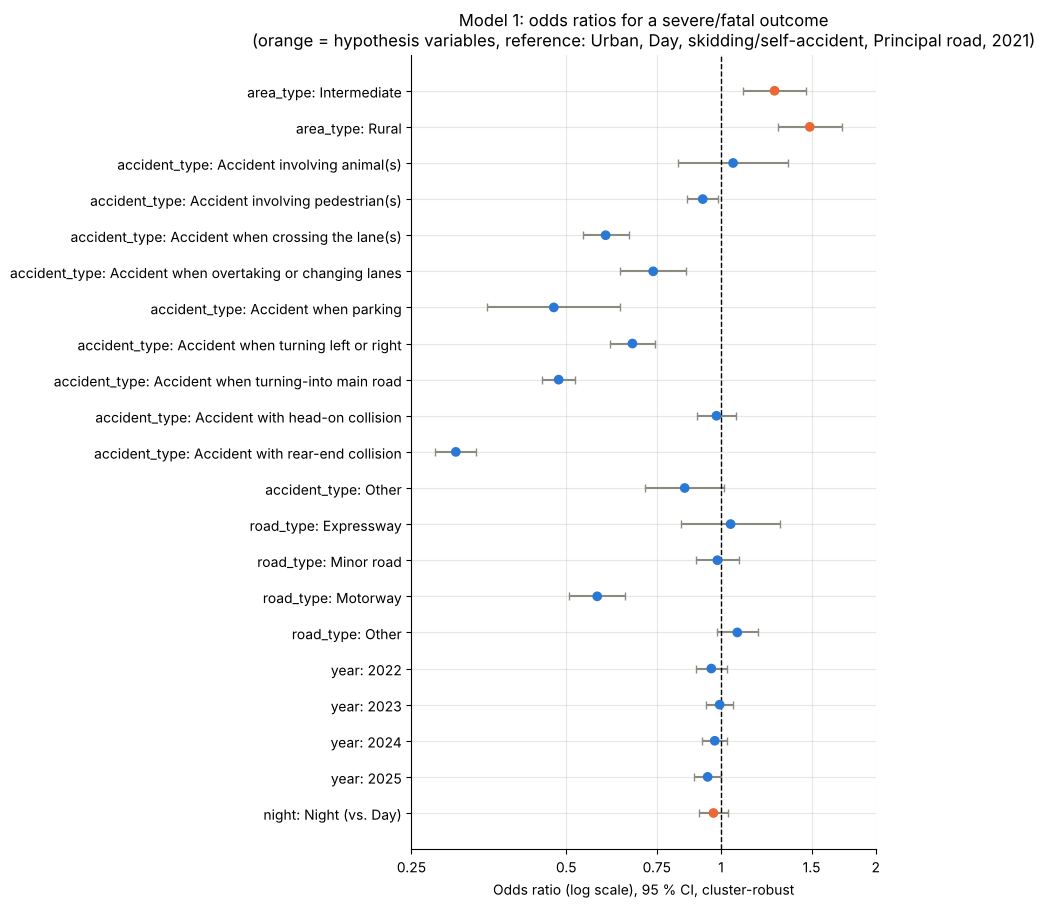

In [8]:
def forest_plot(table, title):
    """Odds ratios with 95 % confidence intervals (without intercept)."""
    t = table.drop(index="Intercept").iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(t) + 1.2))
    colors = [COLOR_NIGHT if (n.startswith("area_type") or n.startswith("night")) else COLOR_MAIN
              for n in t.index]
    ax.errorbar(t["odds_ratio"], range(len(t)),
                xerr=[t["odds_ratio"] - t["ci_low"], t["ci_high"] - t["odds_ratio"]],
                fmt="none", ecolor=COLOR_GREY, capsize=3)
    ax.scatter(t["odds_ratio"], range(len(t)), c=colors, zorder=3)
    ax.axvline(1, color="black", lw=1, ls="--")
    ax.set_yticks(range(len(t)))
    ax.set_yticklabels(t.index)
    ax.set_xscale("log")
    ticks = [0.25, 0.5, 0.75, 1, 1.5, 2]
    ax.set_xticks(ticks)
    ax.set_xticklabels([str(t) for t in ticks])
    ax.minorticks_off()
    ax.set_xlabel("Odds ratio (log scale), 95 % CI, cluster-robust")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

forest_plot(or1, "Model 1: odds ratios for a severe/fatal outcome\n(orange = hypothesis variables, reference: Urban, Day, skidding/self-accident, Principal road, 2021)")

**How to read the chart:** Each dot is an odds ratio, the line is its 95 % confidence interval. The dashed line at 1 means "no difference to the reference group". Dots to the right: higher odds of a severe outcome, to the left: lower odds. If the line does not touch 1, the difference is statistically significant at the 5 % level.

In [9]:
# Key results for H1/H2 (values are read directly from the model output)
for name in ["area_type: Rural", "area_type: Intermediate", "night: Night (vs. Day)"]:
    if name not in or1.index:      # Intermediate is missing if EXCLUDE_INTERMEDIATE = True
        continue
    r = or1.loc[name]
    print(f"{name:28s} OR = {r.odds_ratio:.3f}  (95% CI {r.ci_low:.3f}–{r.ci_high:.3f}),  p = {r.p_value:.4f}")

area_type: Rural             OR = 1.488  (95% CI 1.289–1.718),  p = 0.0000
area_type: Intermediate      OR = 1.271  (95% CI 1.102–1.466),  p = 0.0010
night: Night (vs. Day)       OR = 0.967  (95% CI 0.905–1.033),  p = 0.3157


### Sensitivity check: model 1 without Intermediate municipalities

H1 compares rural with urban municipalities. To check that keeping Intermediate as a separate group does not influence this result, model 1 is estimated again with only Urban and Rural municipalities (same split procedure).

In [10]:
if not EXCLUDE_INTERMEDIATE:
    ur = model_df[model_df["area_type"] != "Intermediate"]
    train_ur, _ = train_test_split(ur, test_size=0.2, stratify=ur["severe"], random_state=RANDOM_STATE)
    model_ur = smf.logit(FORMULA_MAIN, data=train_ur).fit(
        disp=0, cov_type="cluster", cov_kwds={"groups": train_ur["municipality_code"]})
    r = or_table(model_ur).loc["area_type: Rural"]
    print(f"Without Intermediate: OR Rural vs. Urban = {r.odds_ratio:.3f} "
          f"(95% CI {r.ci_low:.3f}–{r.ci_high:.3f}), p = {r.p_value:.4f}")
    print(f"Model 1 (with Intermediate): OR Rural vs. Urban = {or1.loc['area_type: Rural', 'odds_ratio']:.3f}")
else:
    print("EXCLUDE_INTERMEDIATE = True: model 1 above already excludes Intermediate.")

Without Intermediate: OR Rural vs. Urban = 1.479 (95% CI 1.283–1.705), p = 0.0000
Model 1 (with Intermediate): OR Rural vs. Urban = 1.488


### Raw vs. adjusted: what changes when the control variables are added?

To understand the result for H1/H2, the model is built up step by step. In each step the odds ratios for Rural and Night are noted. If an OR becomes smaller when a control variable is added, part of the raw difference is explained by this variable (e.g. different accident types in rural areas or at night).

In [11]:
steps = {
    "1 only area_type + night": "severe ~ C(area_type, Treatment('Urban')) + night",
    "2 + accident_type": "severe ~ C(area_type, Treatment('Urban')) + night"
                         " + C(accident_type, Treatment('Accident with skidding or self-accident'))",
    "3 + road_type": "severe ~ C(area_type, Treatment('Urban')) + night"
                     " + C(accident_type, Treatment('Accident with skidding or self-accident'))"
                     " + C(road_type, Treatment('Principal road'))",
    "4 + year (= model 1)": FORMULA_MAIN,
}
rows = []
for label, f in steps.items():
    m = smf.logit(f, data=train).fit(disp=0, cov_type="cluster",
                                      cov_kwds={"groups": train["municipality_code"]})
    t = or_table(m)
    for name in ["area_type: Rural", "night: Night (vs. Day)"]:
        rows.append({"step": label, "variable": name, "odds_ratio": t.loc[name, "odds_ratio"],
                     "ci_low": t.loc[name, "ci_low"], "ci_high": t.loc[name, "ci_high"],
                     "p_value": t.loc[name, "p_value"]})
stepwise = pd.DataFrame(rows).pivot(index="step", columns="variable",
                                    values=["odds_ratio", "ci_low", "ci_high", "p_value"])
display(stepwise.round(3))

# Composition at night: share of each accident type (training data)
comp = (pd.crosstab(train["accident_type"], train["night"], normalize="columns")
          .rename(columns={0: "share_day", 1: "share_night"}))
comp["share_severe_overall"] = train.groupby("accident_type")["severe"].mean()
display(comp.sort_values("share_night", ascending=False)
            .style.format("{:.1%}"))

odds_ratio                                  ci_low                                 ci_high                                 p_value                       
variable                 area_type: Rural night: Night (vs. Day) area_type: Rural night: Night (vs. Day) area_type: Rural night: Night (vs. Day) area_type: Rural night: Night (vs. Day)
step                                                                                                                                                                                    
1 only area_type + night            1.616                  1.180            1.397                  1.112            1.869                  1.253              0.0                  0.000
2 + accident_type                   1.489                  0.952            1.284                  0.890            1.727                  1.019              0.0                  0.156
3 + road_type                       1.488                  0.966            1.289                  0.904            1.718                  1.032              0.0                  0.304
4 + year (= model 1)                1.488                  0.967            1.289                  0.905            1.718                  1.033              0.0                  0.316

night,share_day,share_night,share_severe_overall
accident_type,,,
Accident with skidding or self-accident,32.9%,69.0%,28.5%
Accident with rear-end collision,18.1%,6.8%,9.7%
Accident involving pedestrian(s),11.3%,5.2%,26.2%
Accident when turning-into main road,12.4%,4.6%,16.2%
Accident when turning left or right,8.2%,3.2%,20.9%
Accident with head-on collision,4.1%,3.1%,29.8%
Accident when overtaking or changing lanes,5.1%,2.8%,21.5%
Accident when crossing the lane(s),5.0%,2.7%,18.8%
Accident involving animal(s),0.3%,1.2%,31.3%


## 6. Model 2: does the night effect differ between urban and rural?

The EDA (section 4 in `02_eda.ipynb`) showed that the night share is clearly higher in urban municipalities but not in rural ones. Model 2 therefore adds an **interaction** `area_type × night`. Important for reading it: with an interaction, the coefficient `night` alone only describes the night effect in the **reference group Urban**. The night effect for Intermediate and Rural is the combination of `night` and the interaction term. It is calculated below as a combined odds ratio with a confidence interval.

H1 and H2 are answered with **model 1**. Model 2 only answers the additional question whether the night effect differs by area type.

In [12]:
FORMULA_INTER = FORMULA_MAIN.replace("+ night", "+ night * C(area_type, Treatment('Urban'))")
model2 = smf.logit(FORMULA_INTER, data=train).fit(
    disp=0, cov_type="cluster", cov_kwds={"groups": train["municipality_code"]})

or2 = or_table(model2)
display(or2.loc[[i for i in or2.index if "night" in i or i.startswith("area_type")]].round(4))

# Joint Wald test: are both interaction terms together equal to 0?
inter_terms = [p for p in model2.params.index if ":" in p]
R = np.zeros((len(inter_terms), len(model2.params)))
for i, term in enumerate(inter_terms):
    R[i, list(model2.params.index).index(term)] = 1
wald = model2.wald_test(R, scalar=True)
print(f"Joint Wald test of the interaction (cluster-robust): chi2 = {float(wald.statistic):.2f}, "
      f"df = {len(inter_terms)}, p = {float(wald.pvalue):.4f}")

,coef,odds_ratio,ci_low,ci_high,p_value
area_type: Intermediate,0.2580,1.2944,1.1203,1.4956,0.0005
area_type: Rural,0.4325,1.5411,1.3330,1.7818,0.0000
night: Night (vs. Day),0.0564,1.0580,0.9807,1.1414,0.1452
night: Night (vs. Day) × area_type: Intermediate,-0.1634,0.8492,0.7325,0.9846,0.0303
night: Night (vs. Day) × area_type: Rural,-0.3273,0.7208,0.6096,0.8523,0.0001


Joint Wald test of the interaction (cluster-robust): chi2 = 16.57, df = 2, p = 0.0003


,OR night vs. day,ci_low,ci_high,p_value
area_type,,,,
Urban,1.058,0.981,1.141,0.145
Intermediate,0.899,0.789,1.023,0.107
Rural,0.763,0.655,0.888,0.000


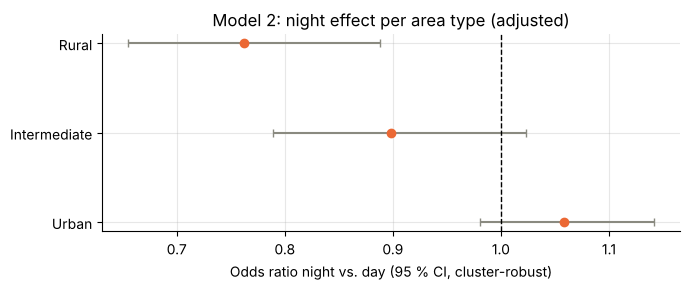

In [13]:
# Night effect per area type = night + interaction term (linear combination)
night_rows = []
for area in [a for a in ["Urban", "Intermediate", "Rural"] if a in set(train["area_type"])]:
    w = pd.Series(0.0, index=model2.params.index)
    w["night"] = 1
    if area != "Urban":
        w[f"night:C(area_type, Treatment('Urban'))[T.{area}]"] = 1
    tt = model2.t_test(w.values)
    est, (lo, hi) = float(tt.effect[0]), tt.conf_int()[0]
    night_rows.append({"area_type": area, "OR night vs. day": np.exp(est),
                       "ci_low": np.exp(lo), "ci_high": np.exp(hi), "p_value": float(tt.pvalue)})
night_by_area = pd.DataFrame(night_rows).set_index("area_type")
display(night_by_area.round(3))

fig, ax = plt.subplots(figsize=(7, 3))
y = range(len(night_by_area))
ax.errorbar(night_by_area["OR night vs. day"], y,
            xerr=[night_by_area["OR night vs. day"] - night_by_area["ci_low"],
                  night_by_area["ci_high"] - night_by_area["OR night vs. day"]],
            fmt="o", color=COLOR_NIGHT, ecolor=COLOR_GREY, capsize=3)
ax.axvline(1, color="black", lw=1, ls="--")
ax.set_yticks(list(y))
ax.set_yticklabels(night_by_area.index)
ax.set_xlabel("Odds ratio night vs. day (95 % CI, cluster-robust)")
ax.set_title("Model 2: night effect per area type (adjusted)")
plt.tight_layout()
plt.show()

**Interpretation:** The joint Wald test of the two interaction terms is significant (p < 0.001): the association between night and severity is **not the same** in all area types.

- **Urban:** night OR ≈ 1.06, confidence interval includes 1, so no clear difference between night and day.
- **Intermediate:** night OR ≈ 0.90, the confidence interval also includes 1.
- **Rural:** night OR ≈ 0.76, the interval lies completely below 1. With the same accident type, road type and year, the *odds* of a severe outcome in rural municipalities are **lower** at night than during the day.

This confirms the descriptive finding of the EDA (rural night share not higher than the day share) and now with control variables and cluster-robust uncertainty. What we cannot say: *why* this is so. Possible explanations (e.g. less traffic and therefore fewer collisions with vulnerable road users at night, or different speeds) are not in the data and would have to be checked separately.

## 7. Model evaluation

The model gives each accident a **predicted probability** of being severe. To turn this into a yes/no prediction, a **threshold** is needed: above the threshold → predicted "severe".

**Class imbalance:** Only about 22 % of the accidents are severe. A trivial model that always predicts "light" is therefore already correct in about 78 % of the cases (accuracy), but finds **no** severe accident. That is why model 1 is compared with this **majority-class baseline**, and why recall, precision and F1 for the class `severe = 1` matter more than accuracy:

- **Recall:** Of all truly severe accidents, how many does the model find?
- **Precision:** Of all accidents predicted as severe, how many are really severe?
- **F1:** Balance of precision and recall (harmonic mean).
- **ROC-AUC:** How well the probabilities separate severe from light accidents, independent of a threshold (0.5 = random guessing, 1 = perfect).

Two thresholds are compared: the default **0.5** and a threshold that maximizes F1 on the **training data** (chosen on training data only, then applied unchanged to the test data, so no information from the test data is used).

Predicted probabilities (test data):
count    17839.000
mean         0.221
std          0.078
min          0.056
25%          0.153
50%          0.244
75%          0.268
max          0.374
dtype: float64
Accidents with predicted probability >= 0.5 (test): 0


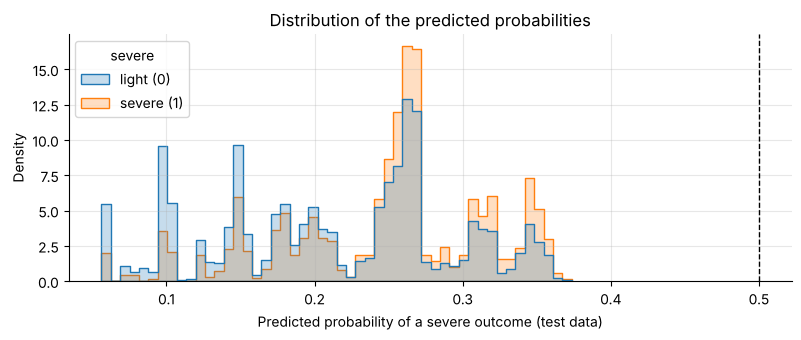

In [14]:
p_train = model1.predict(train)
p_test = model1.predict(test)
y_train, y_test = train["severe"], test["severe"]

print("Predicted probabilities (test data):")
print(p_test.describe().round(3))
print(f"Accidents with predicted probability >= 0.5 (test): {(p_test >= 0.5).sum()}")

fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(x=p_test, hue=y_test.map({0: "light (0)", 1: "severe (1)"}), bins=50,
             stat="density", common_norm=False, element="step", ax=ax)
ax.axvline(0.5, color="black", ls="--", lw=1)
ax.set_xlabel("Predicted probability of a severe outcome (test data)")
ax.set_title("Distribution of the predicted probabilities")
plt.tight_layout()
plt.show()

Threshold with the highest F1 on the training data: 0.21


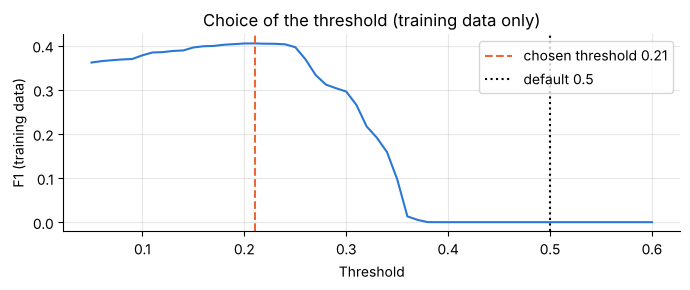

In [15]:
# Choose the threshold on the training data: maximize F1
thresholds = np.round(np.arange(0.05, 0.61, 0.01), 2)
f1_train = [f1_score(y_train, (p_train >= t).astype(int), zero_division=0) for t in thresholds]
best_t = float(thresholds[int(np.argmax(f1_train))])
print(f"Threshold with the highest F1 on the training data: {best_t:.2f}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(thresholds, f1_train, color=COLOR_MAIN)
ax.axvline(best_t, color=COLOR_NIGHT, ls="--", label=f"chosen threshold {best_t:.2f}")
ax.axvline(0.5, color="black", ls=":", label="default 0.5")
ax.set_xlabel("Threshold")
ax.set_ylabel("F1 (training data)")
ax.set_title("Choice of the threshold (training data only)")
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
def scores(y_true, y_pred, y_prob=None):
    """Measures of fit for the class severe = 1. zero_division=0: precision is set to 0
    if a model predicts no severe accident at all (otherwise it would be undefined)."""
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred, zero_division=0),
            "f1": f1_score(y_true, y_pred, zero_division=0),
            "roc_auc": roc_auc_score(y_true, y_prob) if y_prob is not None else np.nan}

# Majority-class baseline (always predicts the most frequent class = 0)
baseline = DummyClassifier(strategy="most_frequent").fit(train[["night"]], y_train)
base_train = baseline.predict(train[["night"]])
base_test = baseline.predict(test[["night"]])
# Second, opposite baseline: always predicts "severe" (finds every severe accident, but with many false alarms)
always_severe_train = np.ones(len(y_train), dtype=int)
always_severe_test = np.ones(len(y_test), dtype=int)

rows = {
    ("train", "Baseline (always 'light')"): scores(y_train, base_train, np.zeros(len(y_train))),
    ("train", "Baseline (always 'severe')"): scores(y_train, always_severe_train, np.ones(len(y_train))),
    ("train", "Model 1, threshold 0.50"): scores(y_train, (p_train >= 0.5).astype(int), p_train),
    ("train", f"Model 1, threshold {best_t:.2f}"): scores(y_train, (p_train >= best_t).astype(int), p_train),
    ("test", "Baseline (always 'light')"): scores(y_test, base_test, np.zeros(len(y_test))),
    ("test", "Baseline (always 'severe')"): scores(y_test, always_severe_test, np.ones(len(y_test))),
    ("test", "Model 1, threshold 0.50"): scores(y_test, (p_test >= 0.5).astype(int), p_test),
    ("test", f"Model 1, threshold {best_t:.2f}"): scores(y_test, (p_test >= best_t).astype(int), p_test),
}
eval_table = pd.DataFrame(rows).T
eval_table.index.names = ["data", "model"]
display(eval_table.style.format("{:.3f}"))

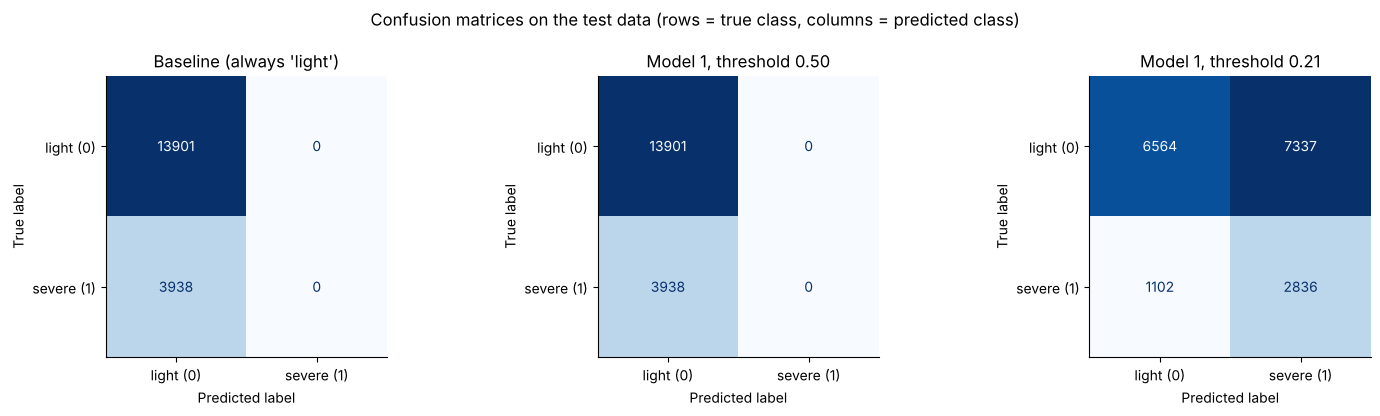

Classification report, model 1 with threshold 0.21 (test data):
              precision    recall  f1-score   support

   light (0)      0.856     0.472     0.609     13901
  severe (1)      0.279     0.720     0.402      3938

    accuracy                          0.527     17839
   macro avg      0.568     0.596     0.505     17839
weighted avg      0.729     0.527     0.563     17839



In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (label, pred) in zip(axes, [("Baseline (always 'light')", base_test),
                                    ("Model 1, threshold 0.50", (p_test >= 0.5).astype(int)),
                                    (f"Model 1, threshold {best_t:.2f}", (p_test >= best_t).astype(int))]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred, labels=[0, 1]),
                           display_labels=["light (0)", "severe (1)"]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(label)
    ax.grid(False)
plt.suptitle("Confusion matrices on the test data (rows = true class, columns = predicted class)")
plt.tight_layout()
plt.show()

print(f"Classification report, model 1 with threshold {best_t:.2f} (test data):")
print(classification_report(y_test, (p_test >= best_t).astype(int),
                            target_names=["light (0)", "severe (1)"], digits=3))

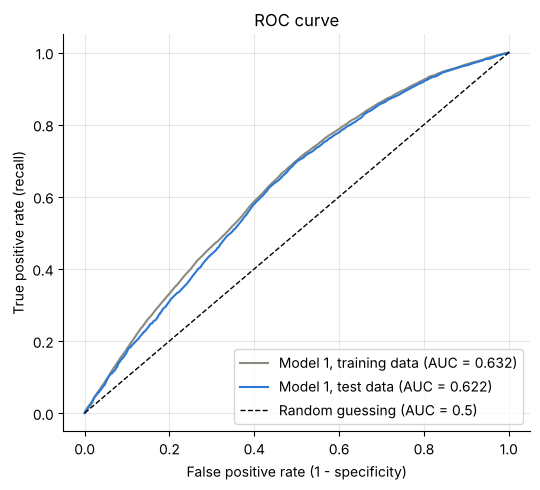

In [18]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for y_true, prob, label, color in [(y_train, p_train, "training data", COLOR_GREY),
                                   (y_test, p_test, "test data", COLOR_MAIN)]:
    fpr, tpr, _ = roc_curve(y_true, prob)
    ax.plot(fpr, tpr, color=color, label=f"Model 1, {label} (AUC = {roc_auc_score(y_true, prob):.3f})")
ax.plot([0, 1], [0, 1], ls="--", color="black", lw=1, label="Random guessing (AUC = 0.5)")
ax.set_xlabel("False positive rate (1 - specificity)")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curve")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Interpretation of the evaluation:**

- **Threshold 0.5:** The highest predicted probability is below 0.4 (see the histogram), so the model never predicts "severe". The result is identical to the majority-class baseline: accuracy ≈ 0.78, but recall = 0. The accuracy of 78 % is therefore **not** a sign of a good model, it only reflects the class distribution.
- **Threshold chosen on the training data (≈ 0.21):** On the test data the model now finds about 72 % of the severe accidents (recall), but only about 28 % of the accidents it flags are really severe (precision). F1 ≈ 0.40. Accuracy drops to about 0.53 because many light accidents are flagged as well (false alarms, see confusion matrix).
- **Compared with the baselines:** The model is better than "always light" (F1 0). Compared with "always severe" (recall 1, precision ≈ 0.22, F1 ≈ 0.36) it is only **moderately** better. This shows that the predictive power is limited.
- **ROC-AUC ≈ 0.62 (test) vs. 0.63 (training):** Clearly better than random guessing (0.5), but far from a good classifier (values from 0.8 are usually considered good).
- **Overfitting:** Training and test values are almost identical. The model does not just memorise the training data. With about 71,000 training accidents and 22 parameters this is expected.

**Conclusion of the evaluation:** The model is suitable for describing **associations** (odds ratios for H1/H2 with control variables). It is **not** suitable for reliably predicting whether a single accident will be severe. Important factors (speed, alcohol, vehicle type, protective equipment, weather) are missing in the data.

## 8. Answer to the hypotheses, limitations and conclusion

### Answer to H1 and H2 (model 1)

| | Raw odds ratio (section 2) | Adjusted odds ratio, model 1 (95 % CI) | p-value | Result |
|---|---|---|---|---|
| **H1** Rural vs. Urban | ≈ 1.60 | ≈ 1.49 (1.29–1.72) | < 0.001 | **supported** |
| (Intermediate vs. Urban) | ≈ 1.31 | ≈ 1.27 (1.10–1.47) | 0.001 | in between |
| **H2** Night vs. Day | ≈ 1.18 | ≈ 0.97 (0.91–1.03) | 0.32 | **not supported** after adjustment |

*(Values rounded from the outputs in sections 2 and 5.)*

**H1 is supported.** With the same accident type, road type and year, the odds of a severe or fatal outcome are about 1.5 times as high in rural as in urban municipalities; the confidence interval lies clearly above 1 even with cluster-robust standard errors. Compared with the raw odds ratio (≈ 1.60) the effect becomes only slightly smaller when the control variables are added, so the different mix of accident types explains only a small part of the urban/rural difference. Intermediate municipalities lie in between. Without the Intermediate municipalities (sensitivity check in section 5) the OR for Rural is practically the same (≈ 1.48).

**H2 is not supported once the control variables are included.** Bivariate, night accidents are more often severe (χ² test in the EDA, raw OR ≈ 1.18). The step-by-step table in section 5 shows that this difference disappears as soon as the **accident type** is added (OR drops from ≈ 1.18 to ≈ 0.95). The composition table explains why: about 69 % of the night accidents are skidding or self-accidents (day: about 33 %), a type with an above-average share of severe outcomes, while rear-end collisions (lowest severity) are rare at night. The higher share of severe accidents at night is therefore associated with **which kinds of accidents happen at night**, not with night itself when the accident type is the same. Model 2 adds that in rural municipalities the adjusted night odds are even lower than during the day.

**Careful wording:** The accident type could itself be part of the reason why night accidents are more severe (e.g. more self-accidents at night). "No night effect with the same accident type" therefore does **not** mean "night does not matter". It means that night has no additional association with severity beyond the type of accident. All results are associations, not causal effects.

### Limitations

- **Only accidents with personal injury:** The data contain only injury accidents. The model compares the severity *given* an injury accident, not the risk of having an accident. There are no exposure data (traffic volume, kilometres driven).
- **Class imbalance:** Only about 22 % of the accidents are severe. This is why the default threshold 0.5 finds no severe accident and why the threshold had to be chosen deliberately. Accuracy alone would be misleading.
- **Weak predictive power:** Accident type, road type, area type, night and year explain only a small part of the severity (low pseudo R², ROC-AUC clearly below 1). Important factors such as speed, alcohol, weather, vehicle type, age or use of a seat belt/helmet are not in the model. The involvement of motorcycles, bicycles and pedestrians is in the data but was deliberately not included, because the model should only contain the agreed control variables; it could act as a confounder (see EDA).
- **Night = clock time:** `night` is defined as 22:00–05:59 and not as actual darkness (which depends on the season).
- **Time and space:** Accidents in the same municipality are similar to each other; this is taken into account with cluster-robust standard errors. Changes over time are only captured by the year categories.
- **Data preparation:** 351 accidents (0.39 %) could not be assigned to a BFS municipality type and are missing (see `01_data.ipynb`).
- **Associations, not causes:** The odds ratios describe associations in the data. They do not show that the area type or the time of day *causes* more severe accidents.

### Conclusion

- **Research question:** Severity of injury accidents is associated with the area type (H1 supported: higher odds in rural municipalities, also after controlling for accident type, road type and year) and strongly with the accident type. The bivariate night difference (H2) is explained by the accident type and is not supported in the adjusted model; the night association even differs by area type.
- **Generalisation:** Training and test results are almost the same (ROC-AUC ≈ 0.63 vs. 0.62), so there is no overfitting. However, the predictive power is weak: the model finds about 72 % of the severe accidents only at the cost of many false alarms.
- **What remains uncertain:** The causes behind the associations (speed, infrastructure, emergency response times, behaviour), the effect of actual darkness instead of clock time, and the influence of variables that are not in the model.

## 9. AI usage log

| Question | Entry |
|---|---|
| **Which tool?** | Claude (model Claude Opus 5.5) in the Claude app, with access to the local repository. Example prompt: *"I am person C. Read the project documents and the repository, make a plan for 03_model.ipynb and ask me what is unclear."* |
| **What helped?** | Reading the existing notebooks, README and project documents and comparing them with the task (e.g. finding that `rural` does not exist and `area_type` has three levels). Setting up the statsmodels formula with fixed reference categories, cluster-robust standard errors, the combined night effect per area type and the evaluation with baseline and threshold. A separate AI review agent checked the plan against the requirements and found gaps (e.g. very small categories, the reading of the interaction model). |
| **What did not work?** | The first draft of the plan treated `year` as decided, although the team had marked it as open. The first explanation of the 267 unassigned accidents (municipality mergers over the years) was wrong: the accident data use the same newer municipality codes for all years. A first model run with threshold 0.5 predicted no severe accident at all; this was not a bug but a consequence of the class imbalance and had to be explained. |
| **Own check / correction** | All key numbers were checked against the EDA tables (section 2: shares 19.90 % / 28.41 %; raw odds ratios recalculated from these shares). A second AI review agent re-ran the notebook and recalculated the numbers; it found wrong numbers in the texts (e.g. a rounded odds ratio, the number of test cases of a small category) and a switch that crashed the notebook, which were corrected. The model results were compared with the raw odds ratios (direction and size). Decisions (Intermediate, year, merged road type) are documented in section 3 and can be switched. |
| **Responsibility** | I can explain: what an odds ratio is and why it is not a probability ratio, why the standard errors are clustered by municipality, why the raw night difference disappears after controlling for accident type, why the threshold 0.5 finds nothing and how recall, precision, F1 and ROC-AUC are read. |

### Jupyter notebook --footer info--

In [19]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.18.44-fc-v653
Datetime: 2026-11-19 11:06:11
Python Version: 3.13.18
-----------------------------------
